# Experiments 17–19: NMR data efficiency

Compare scratch training, a frozen pretrained backbone, and final-interaction-layer transfer across **10, 50, 100, 200 and 800 training structures**. All use the same shared head, fixed element-balanced loss, seed, matched subsets and 50-structure validation set.

The main graph plots **log₁₀(best validation loss) against log₁₀(N)**. These explicit base-10 coordinates are equivalent to a log–log plot. Points are saved checkpoints, not fitted asymptotes. No error bars are shown because there is only one repetition.

**Frozen-backbone results are provisional:** no frozen run reached early stopping. Two reached the epoch ceiling and three stopped earlier; their final epochs are shown in the table. The other ten runs reached early stopping. A plateau in an unfinished run is not evidence of a model's asymptotic limit.


In [1]:
from pathlib import Path
import sys
from IPython.display import display, Image
ROOT = Path(globals().get('PROJECT_ROOT', '/Users/louismcauliffe/code/research/NequIP_experiments'))
sys.path.insert(0, str(ROOT / 'analysis_helpers'))
from learning_curve_review import load_tables, plot_run, plot_method, plot_comparison, plot_rmse
runs, epochs = load_tables(ROOT)
FIGURES = ROOT / 'experiments' / '17-19-LearningCurve-figures'

display(runs[['method','n','best_valid_loss','Si_rmse','O_rmse','best_epoch','final_epoch','status']].round(6))


,method,n,best_valid_loss,Si_rmse,O_rmse,best_epoch,final_epoch,status
0,Scratch,10,0.285961,4.615855,10.447205,62,362,Early stopping
1,Scratch,50,0.111786,3.083778,6.085355,90,390,Early stopping
2,Scratch,100,0.080717,2.649567,5.099450,110,410,Early stopping
3,Scratch,200,0.037884,1.816933,3.488954,114,414,Early stopping
4,Scratch,800,0.010183,0.832985,2.048360,237,537,Early stopping
5,Frozen backbone,10,0.708025,8.163390,14.282294,1507,1507,Stopped before convergence
6,Frozen backbone,50,0.319375,4.630036,11.539410,1612,1612,Stopped before convergence
7,Frozen backbone,100,0.219521,3.820758,9.600807,2996,3000,Epoch ceiling
8,Frozen backbone,200,0.192094,3.564931,8.998561,2993,3000,Epoch ceiling
9,Frozen backbone,800,0.170722,3.389782,8.428298,1751,1755,Stopped before convergence


## Main comparison

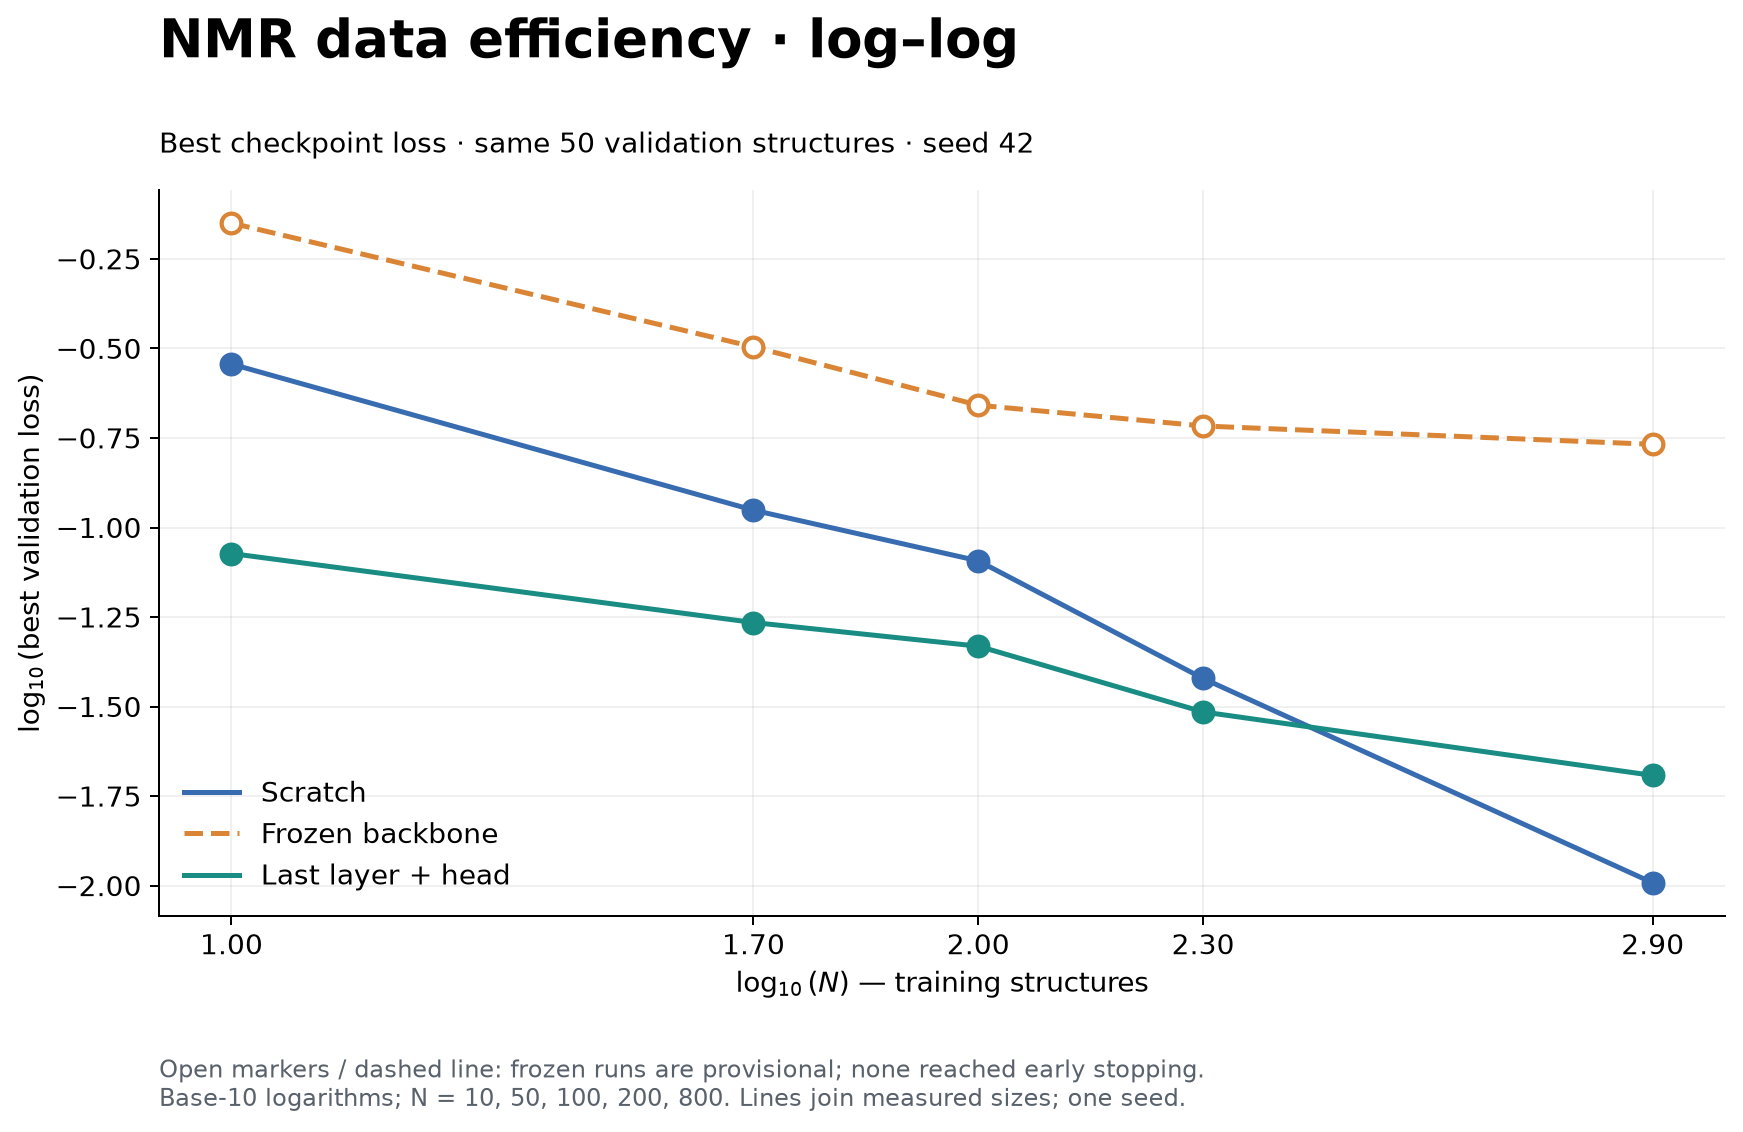

In [2]:
display(Image(filename=str(plot_comparison(runs, FIGURES))))


## Element-wise validation errors

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


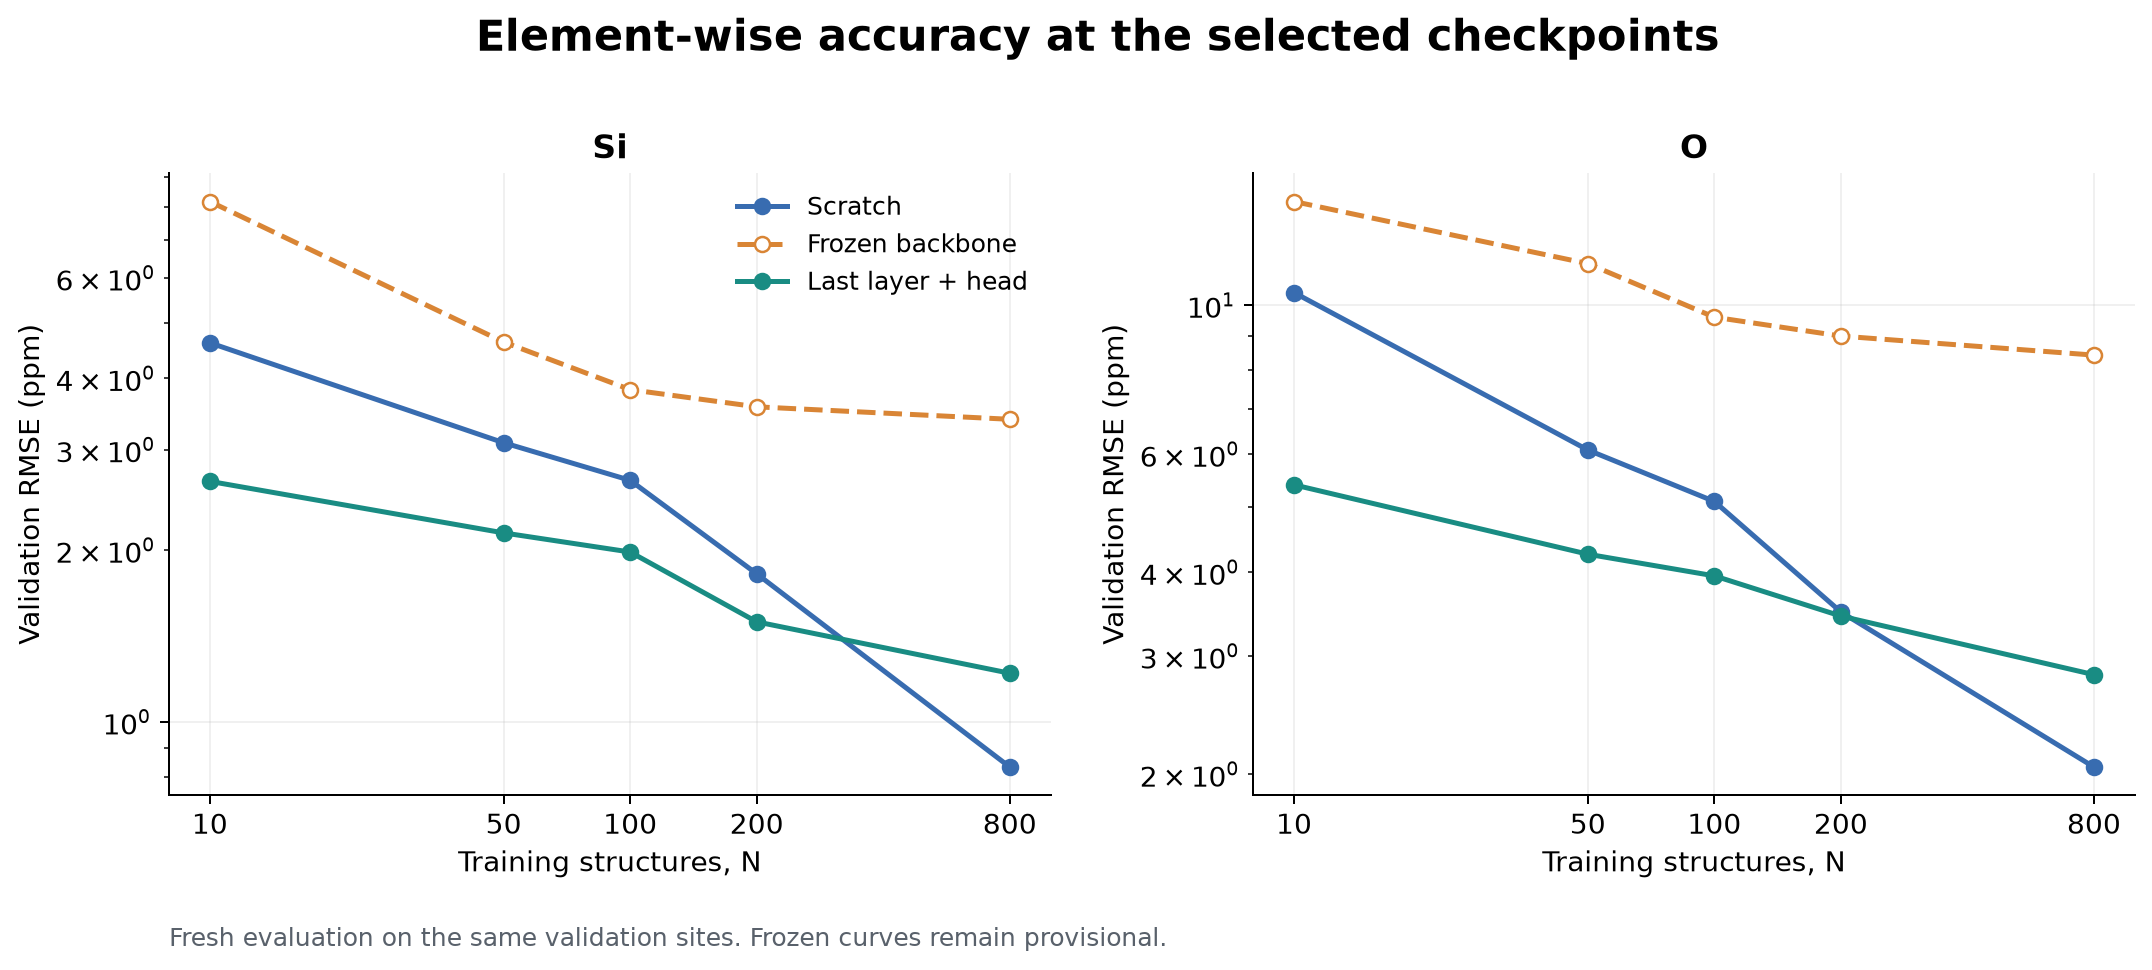

In [3]:
display(Image(filename=str(plot_rmse(runs, FIGURES))))


## Matched-size comparison

In [4]:
pivot = runs.pivot(index='n', columns='experiment', values='best_valid_loss')
comparison = pivot.rename(columns={17:'scratch_loss',18:'frozen_loss',19:'last_layer_loss'}).copy()
comparison['last_layer_reduction_vs_scratch_pct'] = 100 * (1 - pivot[19] / pivot[17])
display(comparison.round(5))
comparison.to_csv(ROOT / 'experiments' / '17-19-LearningCurve-data' / 'matched-size-comparison.csv')


experiment,scratch_loss,frozen_loss,last_layer_loss,last_layer_reduction_vs_scratch_pct
n,,,,
10,0.28596,0.70803,0.08460,70.41487
50,0.11179,0.31938,0.05428,51.44140
100,0.08072,0.21952,0.04663,42.23072
200,0.03788,0.19209,0.03055,19.34623
800,0.01018,0.17072,0.02032,-99.50573


## Interpretation and limits

Final-layer transfer has lower selected validation loss than scratch at N=10, 50, 100 and 200. At N=800, scratch is better. The frozen shared head currently has the highest loss at every size, but its unfinished optimisation prevents a firm saturation conclusion.

This compares the agreed training recipe, not separately optimised hyperparameters or equal compute budgets. Epoch-based stopping means different update counts at different N. Validation data selected the checkpoints, and the normalisation constants were estimated from the full training pool. Repeated seeds and independent test evaluation remain later work.

All best checkpoint exports matched their saved weights, and fresh validation inference reproduced their saved losses within the audit tolerance. Training histories use full-epoch elemental RMSE to reconstruct the common loss, avoiding sampled minibatch values. Individual run histories are in the three experiment notebooks.
